# WP09 — Gerçek protein-PPI eğitimi ve kontrollü ablation

Kullanıcının açık onayıyla frozen v3 protokolünde eğitim yapıldı. **190 fit,10.867 gerçek optimizer adımı,140 inner/50 outer son model.** Protein56→32 tek residual mean PPI;kimya5→8;dört rol ve maskeler. Atom–bağ GNN yoktur;tam moleküler Graph-in-Graph tamamlandı denmez.

**Bilimsel görev:** SIDER'da gözlenen kayıtları yeni ilaçlar için sıralamak. Unknown biyolojik negatif değildir;sigmoid skoru klinik olasılık değildir. Aynı-split sonuçlar önceki baseline'lar görüldüğü için keşifseldir. Bu notebook yalnız kayıtlı çıktıları okur;modeli yeniden fit etmez.

In [1]:
from pathlib import Path
import json,re,numpy as np,pandas as pd,matplotlib.pyplot as plt,networkx as nx
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').is_file():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
QA=ROOT/'reports/qa/WP09/training_v1';MODEL=ROOT/'models/WP09_PPI_v3_training_v1'
FIG=ROOT/'reports/figures/WP09/training_v1';FIG.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_rows',150);pd.set_option('display.max_columns',22);pd.set_option('display.max_colwidth',100)
fit=pd.read_csv(QA/'model_fit_summary.csv');metrics=pd.read_csv(QA/'metrics_with_group_CI.csv');delta=pd.read_csv(QA/'paired_differences_group_CI.csv')
done=json.loads((QA/'training_complete.json').read_text(encoding='utf-8'));run=json.loads((QA/'run_config.json').read_text(encoding='utf-8'))
display(pd.DataFrame([done]).drop(columns=['semantics']))
display(pd.DataFrame([{'model_sürümü':run['version'],'threshold':run['approved_primary_threshold'],'dtype':'float32','CPU_thread':1,
    'atom_bağ_GNN':False,'WP10':False,'B0_B1_B2_refit':False}]))
display(pd.read_csv(QA/'excluded_inner_jobs.csv'))

,version,jobs_recorded,optimizer_steps,fit_status_counts,outer_complete_count,source_positives,source_drugs,source_PT,outer_test_scores_produced,prior_files_verified
0,WP09-protein-PPI-observed-record-v3-training-v1,190,10867,{'OK': 190},10,6416,62,1061,False,1711


,model_sürümü,threshold,dtype,CPU_thread,atom_bağ_GNN,WP10,B0_B1_B2_refit
0,WP09-protein-PPI-observed-record-v3-training-v1,700,float32,1,False,False,False


,context,protocol,outer_fold,inner_fold,model,status,failed_null_replicas,optimizer_steps,prediction_produced
0,primary_o02_i01,primary,2,1,G_noPPI,SKIPPED_SHARED_NULL_FAILURE,2,0,False
1,primary_o02_i01,primary,2,1,G_realPPI,SKIPPED_SHARED_NULL_FAILURE,2,0,False
2,primary_o02_i01,primary,2,1,G_shuffledPPI_R0,SKIPPED_SHARED_NULL_FAILURE,2,0,False
3,primary_o02_i01,primary,2,1,G_shuffledPPI_R1,SKIPPED_SHARED_NULL_FAILURE,2,0,False
4,primary_o02_i01,primary,2,1,G_shuffledPPI_R2,SKIPPED_SHARED_NULL_FAILURE,2,0,False
5,stress_o02_i02,stress,2,2,G_noPPI,SKIPPED_SHARED_NULL_FAILURE,"0,1",0,False
6,stress_o02_i02,stress,2,2,G_realPPI,SKIPPED_SHARED_NULL_FAILURE,"0,1",0,False
7,stress_o02_i02,stress,2,2,G_shuffledPPI_R0,SKIPPED_SHARED_NULL_FAILURE,"0,1",0,False
8,stress_o02_i02,stress,2,2,G_shuffledPPI_R1,SKIPPED_SHARED_NULL_FAILURE,"0,1",0,False
9,stress_o02_i02,stress,2,2,G_shuffledPPI_R2,SKIPPED_SHARED_NULL_FAILURE,"0,1",0,False


**Yorum:** Yapısal null politikası nedeniyle primary_o02_i01 ve stress_o02_i02 bütün varyantlarda seçimden dışarıdadır:10 inner fit çalıştırılmadı. Üç başarısız null eski NA statüsünde kalır. Kalan190 fit teknik hata vermedi;teknik başarı tahmin üstünlüğü veya klinik doğrulama değildir. Dtype float32,CPU1thread ve bütün runtime/CI kararları sonuçlardan önce ayrı onaylı run_config'te kaydedildi;eski proposed v3 dosyası ezilmedi.

## 1. Gerçek loss ve inner doğrulama eğrileri

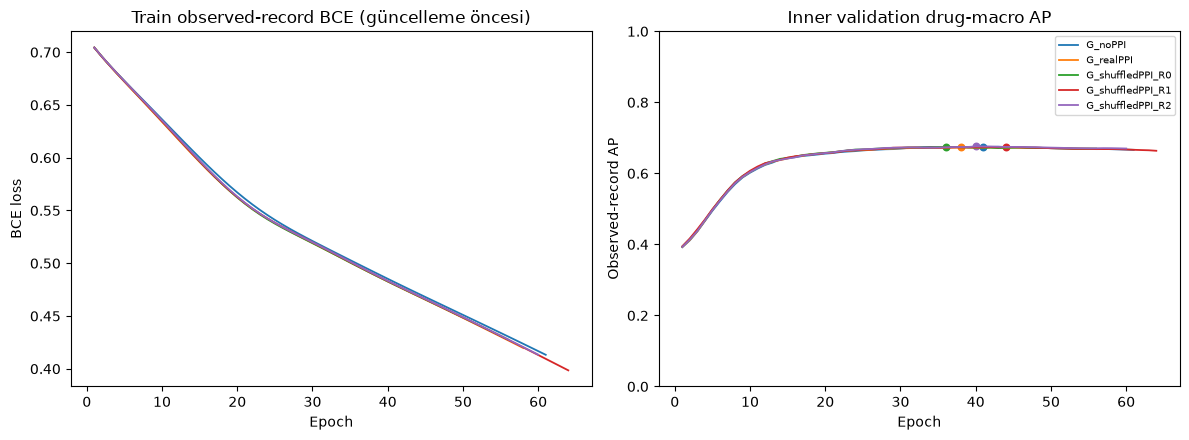

,model,epochs_run,best_epoch,best_validation_AP,optimizer_steps,selected_state_L2_change
0,G_noPPI,61,41,0.675310,61,4.890331
1,G_realPPI,58,38,0.673375,58,4.599551
2,G_shuffledPPI_R0,56,36,0.674183,56,4.457260
3,G_shuffledPPI_R1,64,44,0.674376,64,5.040894
4,G_shuffledPPI_R2,60,40,0.676060,60,4.749456


In [2]:
context='primary_o01_i01';labels=['G_noPPI','G_realPPI','G_shuffledPPI_R0','G_shuffledPPI_R1','G_shuffledPPI_R2']
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
for name in labels:
    row=fit[(fit.context==context)&(fit.model==name)].iloc[0]
    history=pd.read_csv(QA/'history'/(row.job_key+'.csv'))
    axs[0].plot(history.epoch,history.train_BCE_pre_update,label=name,lw=1.3)
    axs[1].plot(history.epoch,history.validation_drug_AP,label=name,lw=1.3)
    selected=history[history.epoch==row.best_epoch].iloc[0]
    axs[1].scatter([row.best_epoch],[selected.validation_drug_AP],s=22)
axs[0].set(title='Train observed-record BCE (güncelleme öncesi)',xlabel='Epoch',ylabel='BCE loss')
axs[1].set(title='Inner validation drug-macro AP',xlabel='Epoch',ylabel='Observed-record AP',ylim=(0,1));axs[1].legend(fontsize=7)
plt.tight_layout();plt.savefig(FIG/'01_real_training_curves.png',dpi=160);plt.show()
display(fit[fit.context.eq(context)][['model','epochs_run','best_epoch','best_validation_AP','optimizer_steps','selected_state_L2_change']])

**Yorum:** Train loss optimizer adımlarıyla değişiyor;inner AP seçilmiş checkpoint'i belirliyor. Patience20/min_delta0,0001 kuralı sabittir;en iyi görülen yeni parametre araması yapılmadı. Noktalar kaydedilmiş best epoch'lardır;son optimizer adımıyla aynı olmak zorunda değildir. Outer test bu eğrilere girmez. Başka fitleri gizlemek için bu örnek seçilmedi:ilk sıralı inner context gösterilir,190 fitin tam eğrileri QA history klasöründedir.

## 2. Outer epoch sayıları nasıl belirlendi?

,protocol,outer_fold,model,best_epoch,optimizer_steps,num_targets,status
15,primary,1,G_noPPI,37,37,240,OK
16,primary,1,G_realPPI,40,40,240,OK
17,primary,1,G_shuffledPPI_R0,36,36,240,OK
18,primary,1,G_shuffledPPI_R1,44,44,240,OK
19,primary,1,G_shuffledPPI_R2,38,38,240,OK
30,primary,2,G_noPPI,44,44,286,OK
31,primary,2,G_realPPI,39,39,286,OK
32,primary,2,G_shuffledPPI_R0,40,40,286,OK
33,primary,2,G_shuffledPPI_R1,39,39,286,OK
34,primary,2,G_shuffledPPI_R2,40,40,286,OK


,protocol,outer_fold,actual_common_inner_folds,common_inner_count,status,outer_test_labels_or_scores_used,outer_all_five_fit_OK
0,primary,1,"[1, 2, 3]",3,SELECTION_COMPLETE,False,True
1,primary,2,"[2, 3]",2,SELECTION_COMPLETE,False,True
2,primary,3,"[1, 2, 3]",3,SELECTION_COMPLETE,False,True
3,primary,4,"[1, 2, 3]",3,SELECTION_COMPLETE,False,True
4,primary,5,"[1, 2, 3]",3,SELECTION_COMPLETE,False,True
5,stress,1,"[1, 2, 3]",3,SELECTION_COMPLETE,False,True
6,stress,2,"[1, 3]",2,SELECTION_COMPLETE,False,True
7,stress,3,"[1, 2, 3]",3,SELECTION_COMPLETE,False,True
8,stress,4,"[1, 2, 3]",3,SELECTION_COMPLETE,False,True
9,stress,5,"[1, 2, 3]",3,SELECTION_COMPLETE,False,True


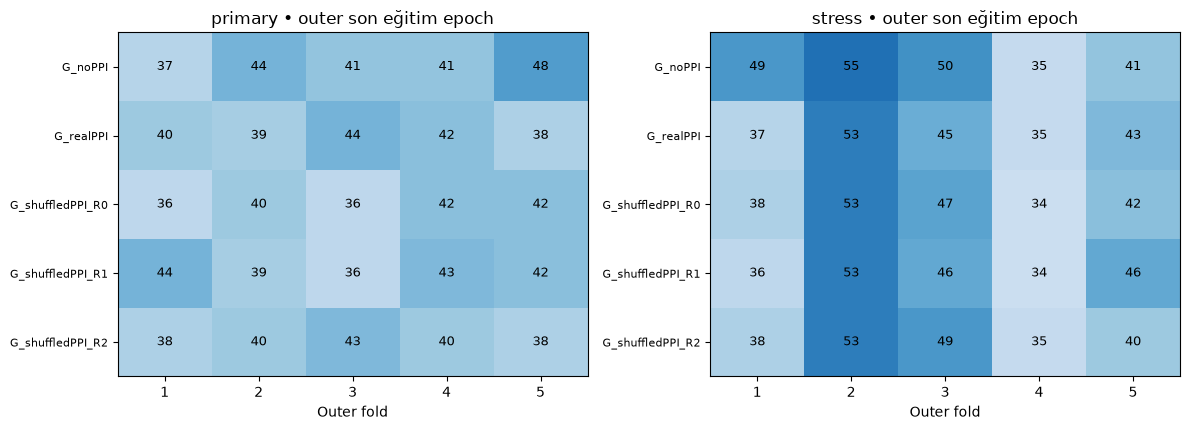

In [3]:
outer=fit[fit.inner_fold.eq(0)]
display(outer[['protocol','outer_fold','model','best_epoch','optimizer_steps','num_targets','status']])
decisions=json.loads((QA/'outer_fit_and_selection.json').read_text(encoding='utf-8'));display(pd.DataFrame(decisions).drop(columns=['outer_epoch_by_model']))
fig,axs=plt.subplots(1,2,figsize=(12,4.4))
for ax,protocol in zip(axs,['primary','stress']):
    heat=outer[outer.protocol.eq(protocol)].pivot(index='model',columns='outer_fold',values='best_epoch').loc[labels]
    ax.imshow(heat,aspect='auto',vmin=25,vmax=65,cmap='Blues');ax.set_xticks(range(5),heat.columns);ax.set_yticks(range(5),heat.index,fontsize=8)
    for i in range(5):
        for j in range(5):ax.text(j,i,str(int(heat.iloc[i,j])),ha='center',va='center',fontsize=9)
    ax.set(title=protocol+' • outer son eğitim epoch',xlabel='Outer fold')
plt.tight_layout();plt.savefig(FIG/'02_outer_epoch_selection.png',dpi=160);plt.show()

**Yorum:** Outer son eğitimleri34–55 epoch sürer. Her variant/null için aynı ortak inner foldlardaki best epoch medyanı .5 yukarı yuvarlanır. Primary outer2 inner2/3,stress outer2 inner1/3 kullanır;diğerleri3 fold. Seçimler önce JSON/hash olarak kaydedildi,bütün outer ağırlıklar tamamlandı,sonra test skorlaması ayrı komutla açıldı. İç sözlükler folda özgüdür;aynı contextte bütün5 fit aynı train ID/head/PT/init hash'ine sahiptir.

## 3. Aynı ortak54 kapsamda B0/B1/B2 ve GNN

,protocol,model,estimate,CI95_low,CI95_high,valid_bootstrap_replicates
0,primary,B2,0.626239,0.579200,0.670094,1000
6,primary,B1,0.655642,0.613111,0.692041,1000
12,primary,B0_all_train,0.646507,0.603990,0.685192,1000
18,primary,B0_like_B2,0.646604,0.604371,0.685339,1000
24,primary,B0_like_B1,0.643787,0.602130,0.681983,1000
30,primary,G_noPPI,0.643021,0.598498,0.684101,1000
36,primary,G_realPPI,0.642880,0.597754,0.684922,1000
42,primary,G_shuffledPPI_R0,0.642240,0.597533,0.683861,1000
48,primary,G_shuffledPPI_R1,0.644285,0.598467,0.685802,1000
54,primary,G_shuffledPPI_R2,0.643252,0.598212,0.685205,1000


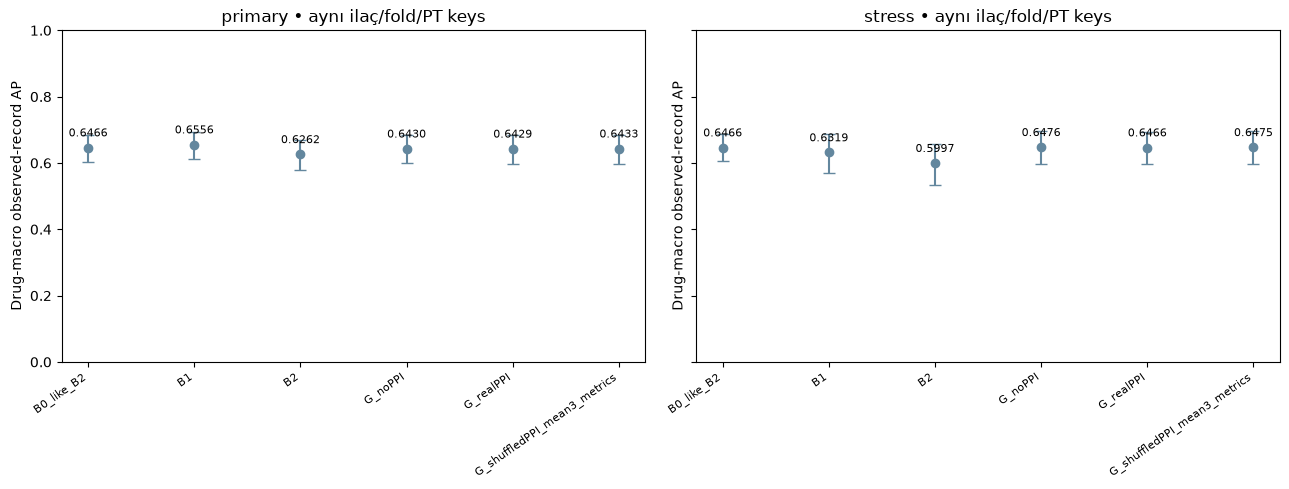

In [4]:
order=['B0_like_B2','B1','B2','G_noPPI','G_realPPI','G_shuffledPPI_mean3_metrics']
ap=metrics[(metrics.scope=='paired54')&(metrics.metric=='drug_macro_AP')]
display(ap[['protocol','model','estimate','CI95_low','CI95_high','valid_bootstrap_replicates']])
fig,axs=plt.subplots(1,2,figsize=(13,5),sharey=True)
for ax,protocol in zip(axs,['primary','stress']):
    sub=ap[ap.protocol.eq(protocol)].set_index('model').loc[order]
    for i,(name,row) in enumerate(sub.iterrows()):
        ax.errorbar(i,row.estimate,yerr=[[row.estimate-row.CI95_low],[row.CI95_high-row.estimate]],fmt='o',capsize=4,color='#63879e')
        ax.annotate(f'{row.estimate:.4f}',(i,row.estimate),xytext=(0,8),textcoords='offset points',ha='center',fontsize=8)
    ax.set_xticks(range(len(order)),order,rotation=35,ha='right',fontsize=8);ax.set(title=protocol+' • aynı ilaç/fold/PT keys',ylabel='Drug-macro observed-record AP',ylim=(0,1))
plt.tight_layout();plt.savefig(FIG/'03_paired_baseline_comparison.png',dpi=160);plt.show()

**Yorum:** Ana ortak54'te G_noPPI0,6430,G_realPPI0,6429,shuffled3 metrik ortalaması0,6433. B1 0,6556,B2 0,6262 ve eşleşen B0_like_B2 0,6466 değişmedi. Gerçek PPI ek drug-AP üstünlüğü göstermedi. Shuffled her R0/R1/R2 ayrı modeldir;tabloda her biri bulunur,primary özet üç metriğin eşit ortalamasıdır. Tahmin skorları ensemble yapılmadı ve en iyi replica seçilmedi. Stres sonuçları B2'ye göre daha iyi görünse de PPI'sız model de aynı kazancı gösterir;PPI katkısı diye sunulamaz.

## 4. PPI katkısı için eşleştirilmiş fark

,protocol,first,reference,first_minus_reference,CI95_low,CI95_high
0,primary,G_realPPI,G_noPPI,-0.000142,-0.003611,0.003248
3,primary,G_realPPI,G_shuffledPPI_mean3_metrics,-0.000379,-0.002039,0.001310
9,primary,G_realPPI,B2,0.016641,-0.000899,0.034086
12,primary,G_realPPI,B0_like_B2,-0.003724,-0.016303,0.007884
48,stress,G_realPPI,G_noPPI,-0.001021,-0.003661,0.001658
51,stress,G_realPPI,G_shuffledPPI_mean3_metrics,-0.000848,-0.001981,0.000294
57,stress,G_realPPI,B2,0.046908,0.025161,0.070822
60,stress,G_realPPI,B0_like_B2,0.000044,-0.013595,0.014030


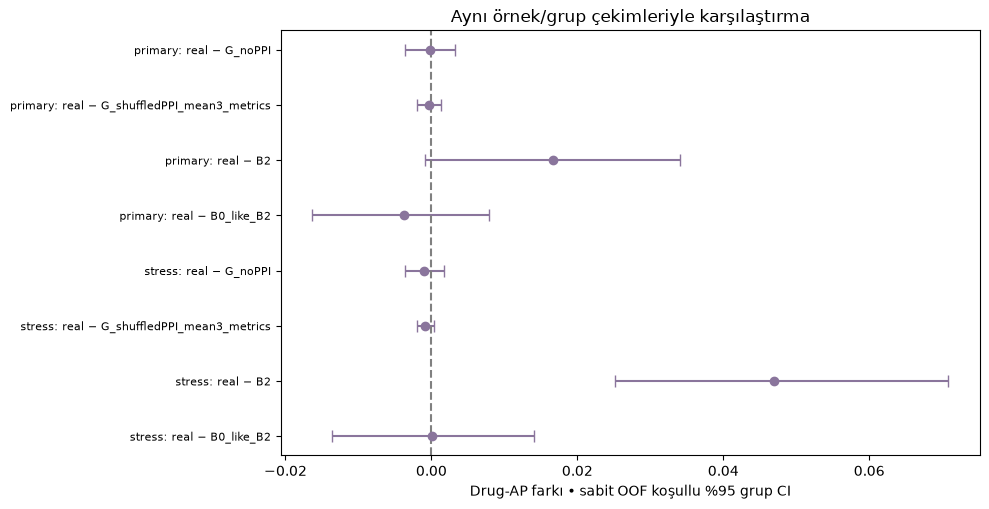

In [5]:
chosen=delta[(delta.scope=='paired54')&(delta.metric=='drug_macro_AP')&(delta['first']=='G_realPPI')&delta.reference.isin(['G_noPPI','G_shuffledPPI_mean3_metrics','B2','B0_like_B2'])]
display(chosen[['protocol','first','reference','first_minus_reference','CI95_low','CI95_high']])
fig,ax=plt.subplots(figsize=(10,5.2));yy=np.arange(len(chosen))
ax.errorbar(chosen.first_minus_reference,yy,xerr=np.vstack([chosen.first_minus_reference-chosen.CI95_low,chosen.CI95_high-chosen.first_minus_reference]),fmt='o',capsize=4,color='#8a759c')
ax.axvline(0,ls='--',color='gray');ax.set_yticks(yy,[f'{r.protocol}: real − {r.reference}' for r in chosen.itertuples()],fontsize=8)
ax.set(xlabel='Drug-AP farkı • sabit OOF koşullu %95 grup CI',title='Aynı örnek/grup çekimleriyle karşılaştırma');ax.invert_yaxis()
plt.tight_layout();plt.savefig(FIG/'04_PPI_paired_differences.png',dpi=160);plt.show()

**Yorum:** Ana real−noPPI −0,000142 (CI−0,003611–+0,003248);real−shuffled_mean −0,000379 (−0,002039–+0,001310). Stres farkları da sıfırı içeren CI verir. PPI'nin kullanıldığını kanıtlamak,bu kaynak ve görevde faydalı olduğunu kanıtlamaz. Real−B2 stres farkı+0,0469 olsa da noPPI−B2+0,0479'dur;kapasite/nonlineer encoder/öğrenme farkı ile topoloji katkısı ayrılmalıdır. Bunlar keşifsel,çoklu karşılaştırmalar;bağımsız dış doğrulama/genel üstünlük kanıtı değildir.

## 5. Micro AP ve fold içi class-AUROC

,protocol,model,metric,estimate,interpretation
1,primary,B2,micro_AP,0.532335,observed-record ranking
4,primary,B2,class_macro_AUROC,0.543061,pooled diagnostic only
5,primary,B2,within_fold_class_macro_AUROC,0.571560,within-fold descriptive mean
7,primary,B1,micro_AP,0.542199,observed-record ranking
10,primary,B1,class_macro_AUROC,0.481439,pooled diagnostic only
11,primary,B1,within_fold_class_macro_AUROC,0.551275,within-fold descriptive mean
19,primary,B0_like_B2,micro_AP,0.586681,observed-record ranking
22,primary,B0_like_B2,class_macro_AUROC,0.328135,pooled diagnostic only
23,primary,B0_like_B2,within_fold_class_macro_AUROC,0.500000,within-fold descriptive mean
31,primary,G_noPPI,micro_AP,0.566156,observed-record ranking


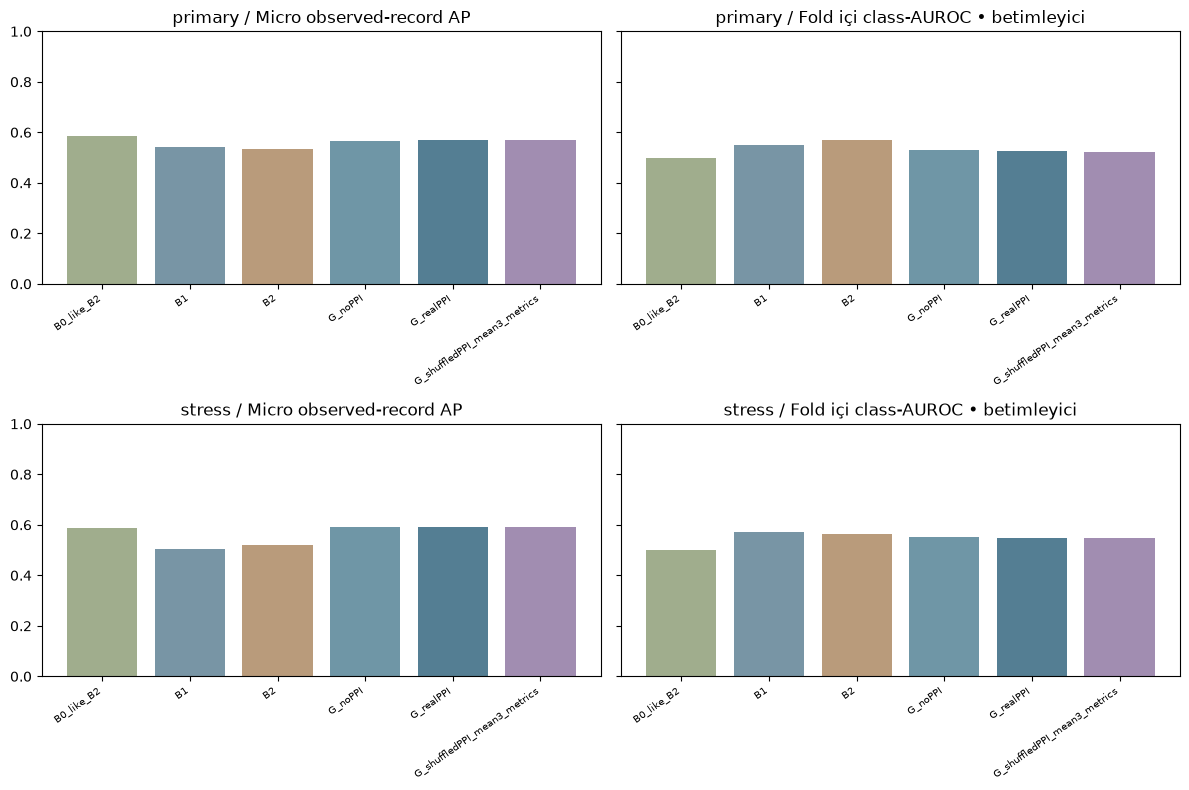

In [6]:
secondary=metrics[(metrics.scope=='paired54')&metrics.metric.isin(['micro_AP','within_fold_class_macro_AUROC','class_macro_AUROC'])&metrics.model.isin(order)]
display(secondary[['protocol','model','metric','estimate','interpretation']])
fig,axs=plt.subplots(2,2,figsize=(12,8),sharey=True)
for i,protocol in enumerate(['primary','stress']):
    for j,(metric,title) in enumerate([('micro_AP','Micro observed-record AP'),('within_fold_class_macro_AUROC','Fold içi class-AUROC • betimleyici')]):
        f=secondary[(secondary.protocol==protocol)&(secondary.metric==metric)].set_index('model').loc[order]
        axs[i,j].bar(range(len(order)),f.estimate,color=['#a0ad8d','#7895a5','#b99b7b','#6f96a6','#547e93','#a18db1'])
        axs[i,j].set_xticks(range(len(order)),order,rotation=35,ha='right',fontsize=7);axs[i,j].set(title=protocol+' / '+title,ylim=(0,1))
plt.tight_layout();plt.savefig(FIG/'05_secondary_metrics.png',dpi=160);plt.show()

**Yorum:** Drug-AP her ilaçta PT sıralaması,micro AP bütün skorlanan çiftlerin pooled sıralaması,class-AUROC aynı PT'de ilaç sıralamasıdır. Fold içi class-AUROC eşit fold ortalaması yalnız betimleyicidir;foldlar bağımsız tekrar sayılmadı. Pooled class-AUROC ayrıca tabloda tanısal tutulur;fold skor ölçekleri/sözlükleri farklı olduğundan klinik ayrım veya tek genel üstünlük diye yorumlanmaz. B0 aynı fold/PT'de sabit skor verdiği için fold içi AUROC0,5'tir. Primary gerçekG microAP0,5678 ve fold içi classAUROC0,5270;stres0,5903/0,5468. Daha iyi görünen özet seçilip primary ölçüt değiştirilmedi.

## 6. Paired54 / own61,unknown,NA ve kapsam dışı pozitifler

,protocol,scope,model,inventory_drugs,expected_comparison_drugs,scored_drugs,AP_evaluable_drugs,expected_scored_pairs,scored_pairs,excluded_comparison_keys,observed_positive_scored,unknown_NOT_verified_negative,source_positive_for_scored_drugs,out_of_scored_vocab_positive,scored_class_union,class_AUROC_evaluable,class_AUROC_NA
6,primary,paired54,G_realPPI,62,54,54,54,13964,13964,0,3820,10144,5505,1685,306,256,50
14,primary,own61,G_realPPI,62,61,61,61,18004,18004,0,4576,13428,6405,1829,350,293,57
24,stress,paired54,G_realPPI,62,54,54,54,13890,13890,0,3751,10139,5505,1754,307,257,50
32,stress,own61,G_realPPI,62,61,61,61,17970,17970,0,4569,13401,6405,1836,351,300,51


,protocol,model,status,ilaç
0,primary,G_noPPI,ABSTAIN_no_input,1
1,primary,G_noPPI,SCORED,61
2,primary,G_realPPI,ABSTAIN_no_input,1
3,primary,G_realPPI,SCORED,61
4,primary,G_shuffledPPI_R0,ABSTAIN_no_input,1
5,primary,G_shuffledPPI_R0,SCORED,61
6,primary,G_shuffledPPI_R1,ABSTAIN_no_input,1
7,primary,G_shuffledPPI_R1,SCORED,61
8,primary,G_shuffledPPI_R2,ABSTAIN_no_input,1
9,primary,G_shuffledPPI_R2,SCORED,61


,status,context_PT_kaydı
0,FITTABLE,9259
1,NA_single_proxy_train_outcome,25


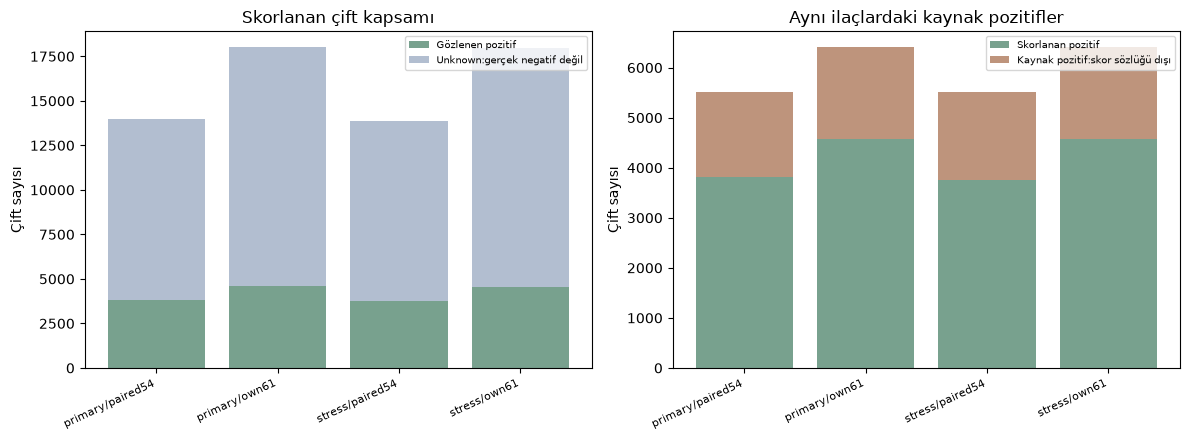

In [7]:
coverage=pd.read_csv(QA/'evaluation_coverage.csv');c=coverage[coverage.model=='G_realPPI']
display(c.drop(columns=['semantics']))
display(pd.read_csv(QA/'prediction_status_all62.csv').groupby(['protocol','model','status']).size().rename('ilaç').reset_index())
target=pd.read_csv(QA/'target_trainability_audit.csv');display(target.groupby('status').size().rename('context_PT_kaydı').reset_index())
fig,axs=plt.subplots(1,2,figsize=(12,4.5));x=np.arange(len(c));names=[f'{r.protocol}/{r.scope}' for r in c.itertuples()]
axs[0].bar(x,c.observed_positive_scored,label='Gözlenen pozitif',color='#78a18e');axs[0].bar(x,c.unknown_NOT_verified_negative,bottom=c.observed_positive_scored,label='Unknown:gerçek negatif değil',color='#b2bed0')
axs[1].bar(x,c.observed_positive_scored,label='Skorlanan pozitif',color='#78a18e');axs[1].bar(x,c.out_of_scored_vocab_positive,bottom=c.observed_positive_scored,label='Kaynak pozitif:skor sözlüğü dışı',color='#be947c')
for ax,title in zip(axs,['Skorlanan çift kapsamı','Aynı ilaçlardaki kaynak pozitifler']):
    ax.set_xticks(x,names,rotation=25,ha='right',fontsize=8);ax.set(title=title,ylabel='Çift sayısı');ax.legend(fontsize=7)
plt.tight_layout();plt.savefig(FIG/'06_coverage_unknown_NA.png',dpi=160);plt.show()

**Yorum:** Her model61/62 ilaçta skor,Methenamine'de abstention verir. Own61 vepaired54 farklı paydadır;B1 own61 tablosuna eksik skorla eklenmez. Kaynak1061 PT ve6416 pozitif korunur;primary paired54'te13964 çift=3820 pozitif+10144 unknown veaynı ilaçlarda1685 kaynak pozitif skor kapsamı dışındadır. Bunlar otomatik negatif/yanlış negatif değildir.306 pooled CUI'nin256'sında class metriği tanımlı,50'sinde NA'dır. Tüm1061 PT'de performans iddiası kurulamaz. Trainability tablosundaki25 single-proxy kaydı40 contextteki PT-sözlük oluşumlarıdır,25 benzersiz ilaç veya25 başarısız model değildir;başlıkta bu hedefler yoktur.

## 7. Önceden seçilmiş gerçek query örneği:Erythromycin

,drug_id,name,MW,LogP,HBD,HBA,TPSA,chem_QC_mask,protein_available,actual_model_job
0,DB00199,Erythromycin,733.937,1.7856,5.0,14.0,193.91,True,True,primary_o03_final_G_realPPI


,rol,accessionlar,sayı
0,target,"[O43193, Q12809]",2
1,enzyme,"[P08684, P20815, P24462]",3
2,transporter,"[O95342, P08183, P46721, Q92887, Q9NPD5, Q9Y6L6]",6
3,carrier,[],0


,rank,class_id,PT_name,score_observed_record_proxy,observed_record_s
0,1,C0042963,Vomiting,0.946601,1
1,2,C0015230,Rash,0.943898,1
2,3,C0011603,Dermatitis,0.916224,0
3,4,C0011991,Diarrhoea,0.904851,1
4,5,C0033774,Pruritus,0.891542,1
5,6,C0002792,Anaphylactic shock,0.886951,1
6,7,C0040034,Thrombocytopenia,0.882341,0
7,8,C0020517,Hypersensitivity,0.875114,1
8,9,C0015967,Body temperature increased,0.854005,0
9,10,C0042109,Urticaria,0.822072,1


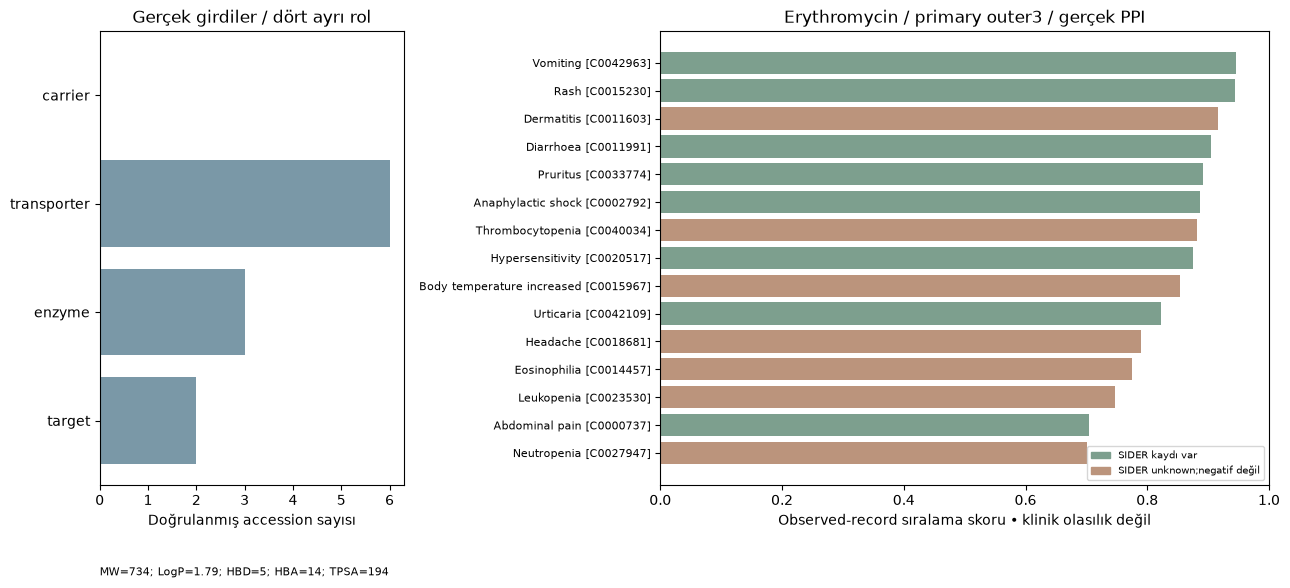

In [8]:
example=json.loads((QA/'example_drug_inputs.json').read_text(encoding='utf-8'));ranking=pd.read_csv(QA/'example_drug_PT_ranking.csv')
display(pd.DataFrame([{'drug_id':example['drug_id'],'name':example['name'],**example['chemistry_source_values'],
    'chem_QC_mask':example['chemistry_QC_mask'],'protein_available':example['protein_available'],'actual_model_job':example['actual_model_job']}]))
display(pd.DataFrame([{'rol':r,'accessionlar':a,'sayı':len(a)} for r,a in example['protein_role_accessions'].items()]))
display(ranking[['rank','class_id','PT_name','score_observed_record_proxy','observed_record_s']].head(20))
top=ranking.head(15).iloc[::-1]
fig,axs=plt.subplots(1,2,figsize=(13,6),gridspec_kw={'width_ratios':[1,2]})
roles=list(example['protein_role_accessions']);axs[0].barh(roles,[len(example['protein_role_accessions'][r]) for r in roles],color='#7a98a7')
axs[0].set(title='Gerçek girdiler / dört ayrı rol',xlabel='Doğrulanmış accession sayısı')
chem='; '.join(f'{k}={v:.3g}' for k,v in example['chemistry_source_values'].items());axs[0].text(0,-.2,chem,transform=axs[0].transAxes,fontsize=8,wrap=True)
axs[1].barh(range(len(top)),top.score_observed_record_proxy,color=np.where(top.observed_record_s.eq(1),'#7d9f8e','#bb947c'))
axs[1].set_yticks(range(len(top)),[f'{r.PT_name} [{r.class_id}]' for r in top.itertuples()],fontsize=8)
axs[1].set(xlim=(0,1),xlabel='Observed-record sıralama skoru • klinik olasılık değil',title='Erythromycin / primary outer3 / gerçek PPI')
from matplotlib.patches import Patch
axs[1].legend(handles=[Patch(color='#7d9f8e',label='SIDER kaydı var'),Patch(color='#bb947c',label='SIDER unknown;negatif değil')],fontsize=7,loc='lower right')
plt.tight_layout();plt.savefig(FIG/'07_real_drug_ranking_example.png',dpi=160);plt.show()

**Yorum:** Örnek ID sonuçlara bakılmadan alfabetik ilk primary paired54 ID'si olarakrun_config'te belirlendi:DB00199 Erythromycin. MW733,937;LogP1,7856;HBD5;HBA14;TPSA193,91 kaynak clean girdileridir. Protein target2/enzyme3/transporter6/carrier0 ayrı tutulur. Bu ilaç primary outer3 test query'sidir;train'e girmemiştir. Renkler değerlendirme sırasında açılan kaynak kayıt durumudur,girdi değildir. Skoru yüksekunknown kavramı gerçek yanlış pozitif veya kesin klinik yan etki değildir. Bu,gerçek girdilerin ve sıralamanın öğretici örneğidir;SHAP/nedensel açıklama değildir. Kaynakta olmayan “risk olasılığı” veya hasta güvenliği önerisi üretilmez.

## 8. Gerçek optimizer/gradient kanıtı

,fit,optimizer_steps,min_weight_change,min_max_message_gradient,max_message_gradient,max_message_input
model,,,,,,
G_noPPI,38,2239,4.190704,0.000000,0.000000,0.000000
G_realPPI,38,2158,3.688938,0.009150,0.018549,24.099337
G_shuffledPPI_R0,38,2149,3.862838,0.007398,0.019315,22.334370
G_shuffledPPI_R1,38,2168,3.965761,0.007840,0.017446,22.401827
G_shuffledPPI_R2,38,2153,3.854052,0.007332,0.017139,22.820646


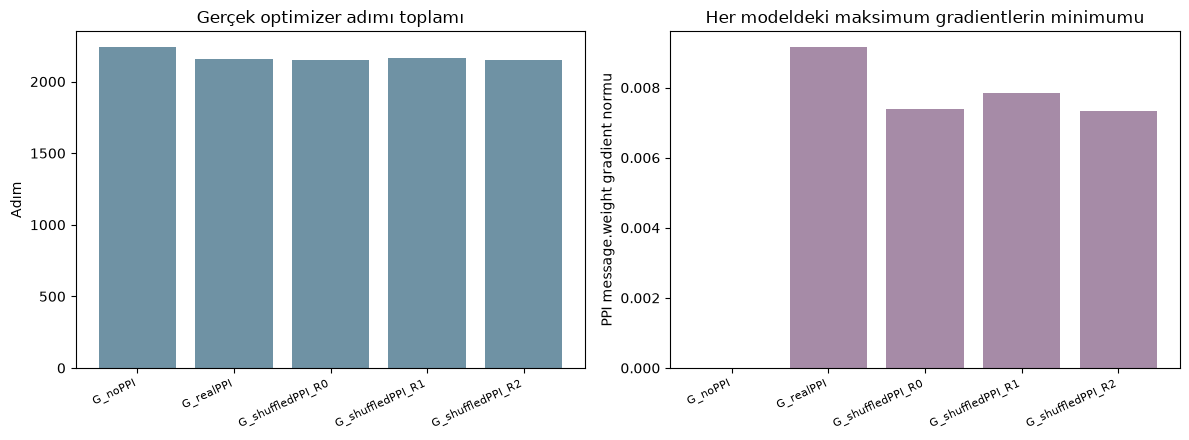

In [9]:
proof=fit.groupby('model').agg(fit=('job_key','count'),optimizer_steps=('optimizer_steps','sum'),
    min_weight_change=('selected_state_L2_change','min'),min_max_message_gradient=('maximum_message_gradient_norm','min'),
    max_message_gradient=('maximum_message_gradient_norm','max'),max_message_input=('maximum_train_message_input_norm','max')).reindex(labels)
display(proof)
fig,axs=plt.subplots(1,2,figsize=(12,4.5));axs[0].bar(range(5),proof.optimizer_steps,color='#6f92a4');axs[0].set(title='Gerçek optimizer adımı toplamı',ylabel='Adım')
axs[1].bar(range(5),proof.min_max_message_gradient,color='#a68ba7');axs[1].set(title='Her modeldeki maksimum gradientlerin minimumu',ylabel='PPI message.weight gradient normu')
for ax in axs:ax.set_xticks(range(5),labels,rotation=25,ha='right',fontsize=8)
plt.tight_layout();plt.savefig(FIG/'08_optimizer_gradient_evidence.png',dpi=160);plt.show()
import plotly.graph_objects as go
drug=pd.read_csv(QA/'per_drug_metrics.csv');sub=drug[(drug.protocol=='primary')&(drug.scope=='paired54')&drug.model.isin(['G_noPPI','G_realPPI'])]
pivot=sub.pivot(index='drug_id',columns='model',values='drug_AP')
interactive=go.Figure([go.Scatter(x=pivot.G_noPPI,y=pivot.G_realPPI,mode='markers',text=pivot.index,hovertemplate='%{text}<br>noPPI AP=%{x:.4f}<br>realPPI AP=%{y:.4f}<extra></extra>'),go.Scatter(x=[0,1],y=[0,1],mode='lines',line=dict(dash='dash',color='gray'),hoverinfo='skip')])
interactive.update_layout(title='Primary paired54 • ilaç bazlı observed-record AP;klinik risk değil',xaxis_title='G_noPPI drug AP',yaxis_title='G_realPPI drug AP',showlegend=False)
interactive.write_html(FIG/'per_drug_ablation_interactive.html',include_plotlyjs=True,full_html=True)

**Yorum:** Tüm190 fitte ağırlıklar değişti. Real/shuffled mesaj gradienti her fitte sıfırdan farklı;noPPI mesaj girdisi/gradienti0. NoPPI'da kullanılmayan message ağırlığınınAdamW weight decay ile sayısal kayması komşuluk kullanımı sayılmaz;kanıt gerçek gradient/input/forward testidir. ÖncekiV6'nın“PPI var ama forward yok” hatası giderilmiştir,fakat performans ablation'ı bu görevde ek fayda göstermemiştir. Etkileşimli HTML ilaç bazlı AP kıyasını incelemek içindir;offlinePlotly içerir,canlı tarayıcı testi yapılmadı.

## 9. Testler,tekrar üretim ve durma noktası

In [10]:
text=(QA/'test_results.txt').read_text(encoding='utf-8');test=re.search(r'Ran ([0-9]+) tests in ([0-9.]+)s',text)
display(pd.DataFrame([{'gerçek_trainer_testi':int(test.group(1)),'saniye':float(test.group(2)),'tümü_geçti':text.rstrip().endswith('OK'),
    'korunan_önceki_dosya':done['prior_files_verified'],'base_seed':20261106,'WP10':False}]))
display(pd.read_csv(QA/'feature_fit_provenance.csv').head(5))
display(pd.DataFrame([json.loads((QA/'evaluation_complete.json').read_text(encoding='utf-8'))]).drop(columns=['semantics']))

,gerçek_trainer_testi,saniye,tümü_geçti,korunan_önceki_dosya,base_seed,WP10
0,24,17.025,True,1711,20261106,False


,job_key,context,model,classifier_fit_drug_ids,chemistry_scaler_fit_ids,protein_scaler_fit_accessions,preprocessing_refit,source,semantics
0,primary_o01_final_G_noPPI,primary_o01_final,G_noPPI,"[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415"", ""DB0041...","[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415"", ""DB0041...","[""A0A0H2XJ39"", ""D6R448"", ""O15244"", ""O15439"", ""O25608"", ""O43193"", ""O76082"", ""O94956"", ""O95342"", ""...",False,frozen WP08 transform_fit_sources_and_statistics.json,Observed SIDER record ranking proxy; unknown NOT verified biological negative; not clinical risk...
1,primary_o01_final_G_realPPI,primary_o01_final,G_realPPI,"[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415"", ""DB0041...","[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415"", ""DB0041...","[""A0A0H2XJ39"", ""D6R448"", ""O15244"", ""O15439"", ""O25608"", ""O43193"", ""O76082"", ""O94956"", ""O95342"", ""...",False,frozen WP08 transform_fit_sources_and_statistics.json,Observed SIDER record ranking proxy; unknown NOT verified biological negative; not clinical risk...
2,primary_o01_final_G_shuffledPPI_R0,primary_o01_final,G_shuffledPPI_R0,"[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415"", ""DB0041...","[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415"", ""DB0041...","[""A0A0H2XJ39"", ""D6R448"", ""O15244"", ""O15439"", ""O25608"", ""O43193"", ""O76082"", ""O94956"", ""O95342"", ""...",False,frozen WP08 transform_fit_sources_and_statistics.json,Observed SIDER record ranking proxy; unknown NOT verified biological negative; not clinical risk...
3,primary_o01_final_G_shuffledPPI_R1,primary_o01_final,G_shuffledPPI_R1,"[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415"", ""DB0041...","[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415"", ""DB0041...","[""A0A0H2XJ39"", ""D6R448"", ""O15244"", ""O15439"", ""O25608"", ""O43193"", ""O76082"", ""O94956"", ""O95342"", ""...",False,frozen WP08 transform_fit_sources_and_statistics.json,Observed SIDER record ranking proxy; unknown NOT verified biological negative; not clinical risk...
4,primary_o01_final_G_shuffledPPI_R2,primary_o01_final,G_shuffledPPI_R2,"[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415"", ""DB0041...","[""DB00199"", ""DB00207"", ""DB00259"", ""DB00301"", ""DB00303"", ""DB00319"", ""DB00359"", ""DB00415"", ""DB0041...","[""A0A0H2XJ39"", ""D6R448"", ""O15244"", ""O15439"", ""O25608"", ""O43193"", ""O76082"", ""O94956"", ""O95342"", ""...",False,frozen WP08 transform_fit_sources_and_statistics.json,Observed SIDER record ranking proxy; unknown NOT verified biological negative; not clinical risk...


,elapsed_seconds,bootstrap_reps,OOF_predictions_sha256,selection_commit_sha256,WP08_scores_sha256_unchanged,WP08_C_sha256_unchanged,refit_or_retuning,no_prediction_ensemble,prior_files_verified,WP10
0,71.482561,1000,ad9fabf7ee6d01c0c93c89c3d7ee682064118d4892030bf51b2f753da36e293b,28a977d9c0dd0b6f9b61f71eb3bf92d5f3694b200721096ce560f51cfb36625e,e4b8be02329ce0f6b5cb78083a6426cde12336fe7979718951f293a12cff77aa,5e20e8df3aa05d2a74cf67eb3abae565fe13fd6ad339eefebe6800ac431ff2c6,False,True,1711,False


**Yorum:**24 test gerçek optimizer,init/epoch/ID/PT kaynağı,kayıtlı parametreden skor,aynıouter fit tekrar üretimi,gerçektrainer'da outer label/value mutation,train-state/query izolasyonu,trained PPI/noPPI forward,kusurda NA,bağımsızsklearn AP ve kapsam testlerini içerir. Testlerin küçük kontrollü yeniden fit'leri model dosyalarını değiştirmez,protokol veya parametre araması değildir.

CI1000 paired structural-group bootstrap'tır;ana61/stres40 grup birlikte örneklenir ve modeller aynı çekimleri kullanır. SabitOOF ve üç sabit null'a koşulludur;tam tekrar-eğitim/initialization/null dağılımı/dış kohort belirsizliğini kapsamaz. Null'lar bağımsız hasta/ilaç örneği değildir.

[Eğitim raporu](../reports/WP09_TRAINING_RESULTS.md) ve [model kartı](../reports/WP09_TRAINING_MODEL_CARD.md) nihai bulgu/sınırları açıklar. **WP09 eğitim/değerlendirmesi bittiğinde durulur;WP10'a geçmek için kullanıcı onayı gerekir.**